In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## installing dependencies

In [3]:
!pip install ultralytics
!pip install opencv-python
!pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 58.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


## analyzing datasets does all images contains annotaios or not no of images etc

In [4]:
import os, random, shutil
import cv2
import matplotlib.pyplot as plt

Datasets = os.path.join('/content/drive/MyDrive', 'datasets')
Dataset = os.path.join(Datasets, 'Newspaper-Ads-Detection-6')   # copy the name exactly from your listing
train_data = os.path.join(Dataset, 'train')
imgs = os.path.join(train_data, 'images')
labels = os.path.join(train_data, 'labels')

image_files = []
for item in sorted(os.listdir(imgs)):
    if item.lower().endswith(('.jpg', '.jpeg', '.png')):
        image_files.append(item)
print('images:', len(image_files))
print('label files:', len(os.listdir(labels)))
print(open(os.path.join(Dataset, 'data.yaml')).read())          # check the class names

images: 1072
label files: 1072
names:
- advertisement
nc: 1
roboflow:
  license: CC BY 4.0
  project: newspaper-ads-detection
  url: https://universe.roboflow.com/university-of-cologne/newspaper-ads-detection/dataset/6
  version: 6
  workspace: university-of-cologne
test: ../test/images
train: ../train/images
val: ../valid/images



In [5]:
empty_files = []      # pages with no ad
ad_files = []         # pages with at least one ad
class_count = {}
bad_rows = 0
for item in image_files:
    name = os.path.splitext(item)[0]
    label_path = os.path.join(labels, name + '.txt')
    rows = []
    if os.path.exists(label_path):
        for line in open(label_path).read().splitlines():
            if line.strip() != '':
                rows.append(line.split())
    if len(rows) == 0:
        empty_files.append(item)
    else:
        ad_files.append(item)
    for row in rows:
        class_count[row[0]] = class_count.get(row[0], 0) + 1
        if len(row) != 5:
            bad_rows += 1
print('pages with no ads:', len(empty_files), 'out of', len(image_files))
print('boxes per class id:', class_count)
print('bad rows (not 5 numbers):', bad_rows)

pages with no ads: 384 out of 1072
boxes per class id: {'0': 2542}
bad rows (not 5 numbers): 0


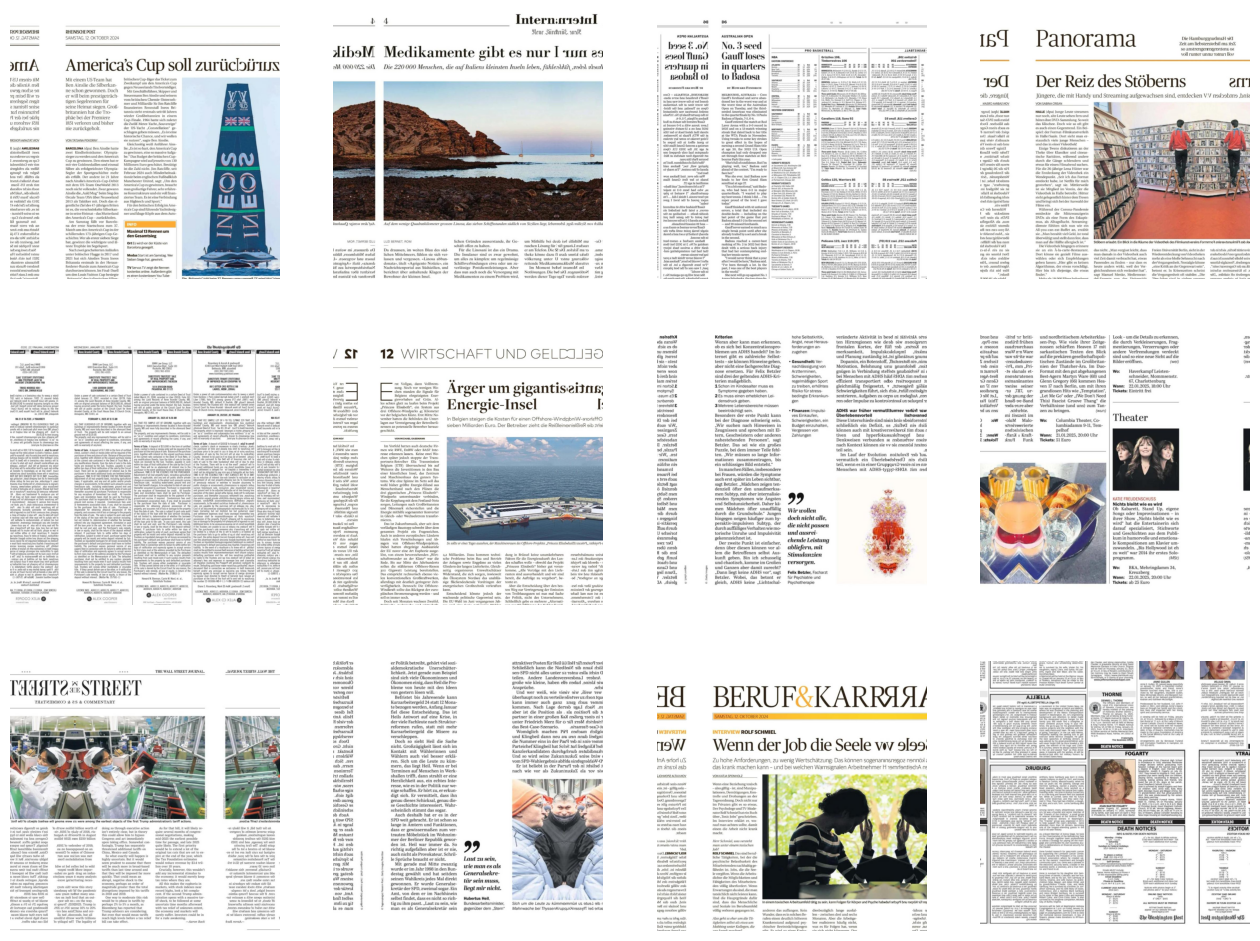

In [6]:
random.seed(1)
sample = random.sample(empty_files, 12)
plt.figure(figsize=(16, 12))
for i in range(12):
    img = cv2.cvtColor(cv2.imread(os.path.join(imgs, sample[i])), cv2.COLOR_BGR2RGB)
    plt.subplot(3, 4, i + 1)
    plt.imshow(img)
    plt.axis('off')
plt.show()

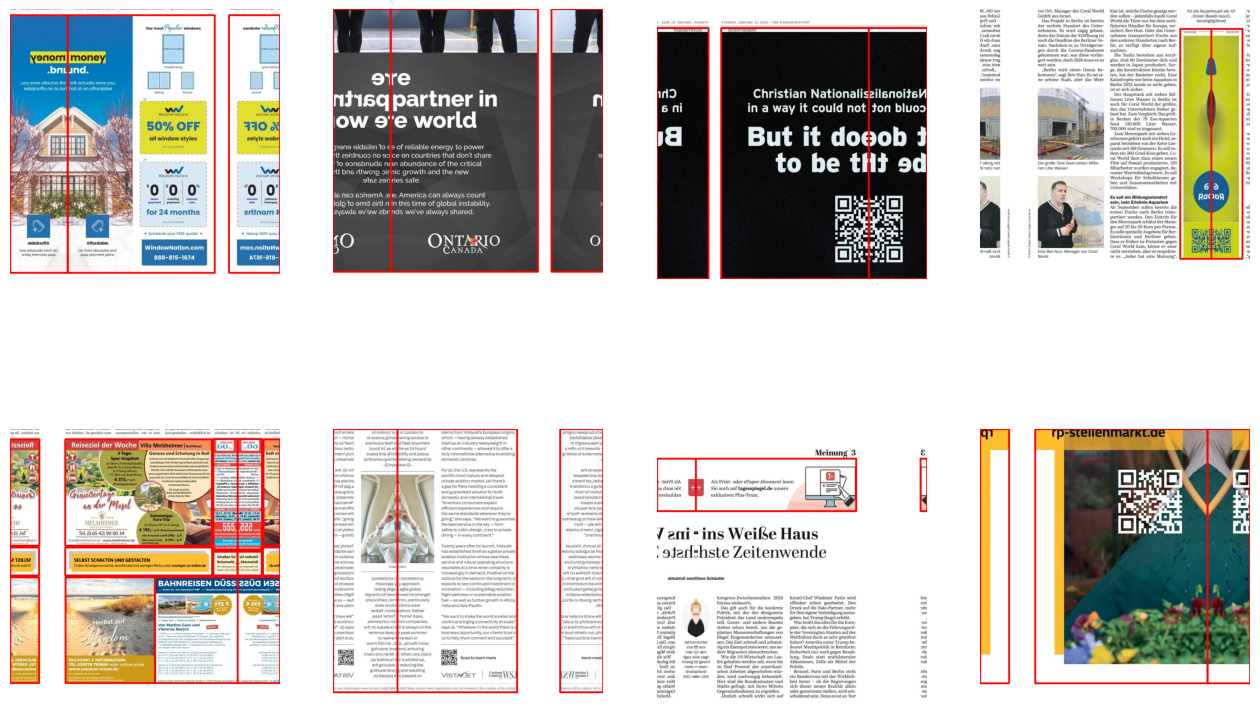

In [7]:
random.seed(2)
sample = random.sample(ad_files, 8)
plt.figure(figsize=(16, 10))
for i in range(8):
    img = cv2.cvtColor(cv2.imread(os.path.join(imgs, sample[i])), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    name = os.path.splitext(sample[i])[0]
    for line in open(os.path.join(labels, name + '.txt')).read().splitlines():
        c, x, y, bw, bh = line.split()[:5]
        x, y, bw, bh = float(x) * w, float(y) * h, float(bw) * w, float(bh) * h
        cv2.rectangle(img, (int(x - bw / 2), int(y - bh / 2)), (int(x + bw / 2), int(y + bh / 2)), (255, 0, 0), max(3, w // 150))
    plt.subplot(2, 4, i + 1)
    plt.imshow(img)
    plt.axis('off')
plt.show()

## Train , Test and Validation splitting

In [8]:
OUT = '/content/ds'
if os.path.exists(OUT):
    shutil.rmtree(OUT)                       # start clean so re-running never mixes old and new files

shuffled = image_files[:]
random.seed(0)
random.shuffle(shuffled)
n = len(shuffled)
splits = {
    'train': shuffled[:int(0.8 * n)],
    'val': shuffled[int(0.8 * n):int(0.9 * n)],
    'test': shuffled[int(0.9 * n):],
}

for split in splits:
    os.makedirs(os.path.join(OUT, 'images', split))
    os.makedirs(os.path.join(OUT, 'labels', split))
    no_ad = 0
    for item in splits[split]:
        name = os.path.splitext(item)[0]
        shutil.copy(os.path.join(imgs, item), os.path.join(OUT, 'images', split, item))
        label_path = os.path.join(labels, name + '.txt')
        new_label = os.path.join(OUT, 'labels', split, name + '.txt')
        if os.path.exists(label_path):
            shutil.copy(label_path, new_label)
        else:
            open(new_label, 'w').close()     # no label file = empty file = no ad
        if os.path.getsize(new_label) == 0:
            no_ad += 1
    print(split, ':', len(splits[split]), 'images,', no_ad, 'with no ads')

train : 857 images, 308 with no ads
val : 107 images, 37 with no ads
test : 108 images, 39 with no ads


In [9]:
text = "path: /content/ds\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n  0: ad\n"
open(os.path.join(OUT, 'data.yaml'), 'w').write(text)
print(open(os.path.join(OUT, 'data.yaml')).read())

path: /content/ds
train: images/train
val: images/val
test: images/test
names:
  0: ad



## Fine Tunning a Yolo v11s Model on our dataset

In [10]:
from ultralytics import YOLO

model = YOLO('yolo11s.pt')        # if this name is rejected, use 'yolov8s.pt'
model.train(data='/content/ds/data.yaml', epochs=100, imgsz=1024, batch=8, fraction=0.1,
            project='/content/drive/MyDrive/ad_runs', name='smoke', exist_ok=True)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/ds/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=0.1, freeze=Non

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7e0760e64c20>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

## Evaluating

In [11]:
best = YOLO('/content/drive/MyDrive/ad_runs/ad_s_1024/weights/best.pt')
m = best.val(data='/content/ds/data.yaml', split='test', imgsz=1024, conf=0.25)
print('precision:', m.box.mp)
print('recall:', m.box.mr)
print('mAP50:', m.box.map50)
print('mAP50-95:', m.box.map)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 32.7±20.0 MB/s, size: 150.8 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/ds/labels/test... 108 images, 39 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 108/108 294.4it/s 0.4s
val: New cache created: /content/ds/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 1.5it/s 4.6s
                   all        108        266      0.811      0.857       0.83      0.764
Speed: 6.1ms preprocess, 23.3ms inference, 0.0ms loss, 1.6ms postprocess per image
Results saved to /content/runs/detect/val
precision: 0.810778872463743
recall: 0.8571428571428571
mAP50: 0.830038079724945



0: 1024x1024 11 ads, 23.0ms
1: 1024x1024 6 ads, 23.0ms
2: 1024x1024 3 ads, 23.0ms
3: 1024x1024 (no detections), 23.0ms
4: 1024x1024 (no detections), 23.0ms
5: 1024x1024 6 ads, 23.0ms
6: 1024x1024 (no detections), 23.0ms
7: 1024x1024 2 ads, 23.0ms
Speed: 3.6ms preprocess, 23.0ms inference, 1.0ms postprocess per image at shape (1, 3, 1024, 1024)


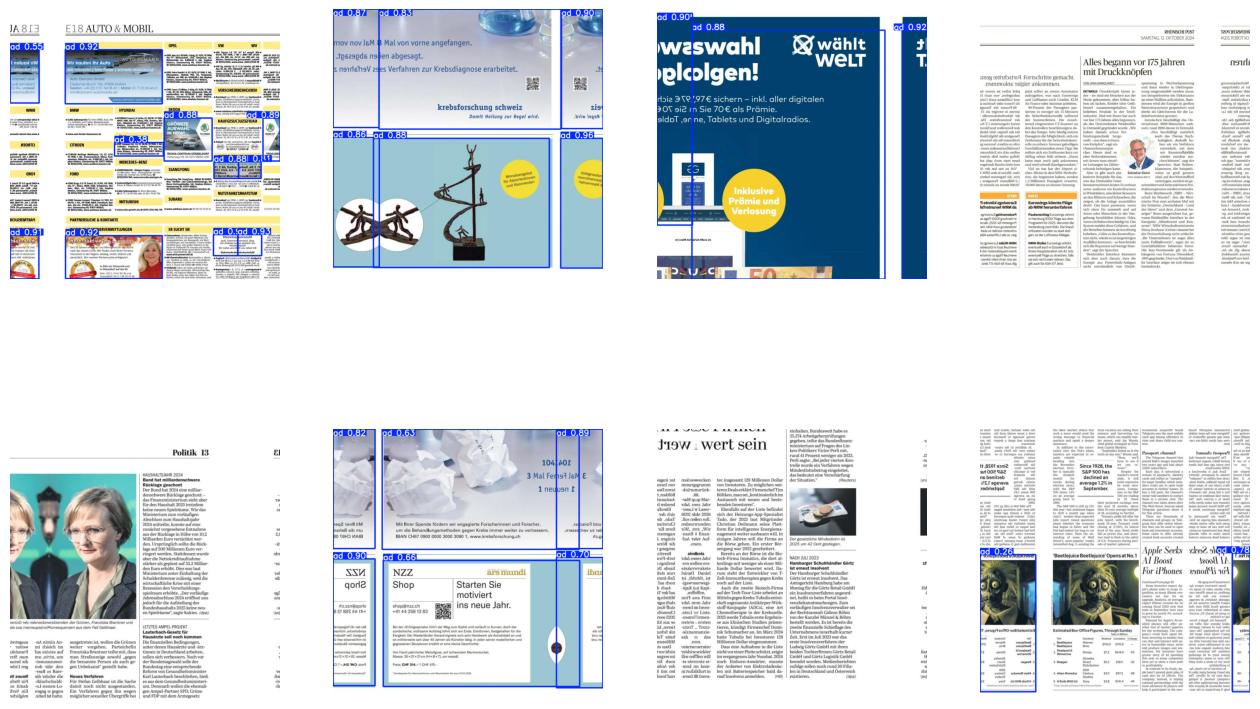

In [12]:
import glob, random
import matplotlib.pyplot as plt

files = sorted(glob.glob('/content/ds/images/test/*'))
random.seed(3)
sample = random.sample(files, 8)
results = best.predict(sample, imgsz=1024, conf=0.25)

plt.figure(figsize=(16, 10))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(results[i].plot()[:, :, ::-1])
    plt.axis('off')
plt.show()

In [13]:
from google.colab import drive, files
import os, shutil
src = '/content/drive/MyDrive/ad_runs/ad_s_1024/weights/best.pt'
print('exists:', os.path.exists(src), '| size MB:', round(os.path.getsize(src) / 1e6, 1) if os.path.exists(src) else '-')

shutil.copy(src, '/content/ad_best.pt')    # copy to local disk first; downloads from a Drive path can be flaky
files.download('/content/ad_best.pt')

exists: True | size MB: 19.3


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>